# Machine Unlearning cho PhoBERT trên UIT-VSFC

Ba kịch bản quên (`CFG["modes"]`):
- **random**: quên ngẫu nhiên 5% mẫu, mô phỏng người dùng yêu cầu xóa dữ liệu.
- **topic**: quên toàn bộ một chủ đề (mặc định *facility*), mô phỏng xóa theo nguồn. Kèm đo **thiệt hại phụ** lên các chủ đề khác.
- **noisy**: 5% mẫu bị lật nhãn và cần được quên, mô phỏng xóa dữ liệu "khó" mà mô hình buộc phải ghi nhớ. Mô hình gốc được huấn luyện lâu hơn (8 epoch, tự thêm nếu cần) để thực sự ghi nhớ các nhãn này; Retrain dùng cùng lịch huấn luyện.

Ngoài 5 phương pháp chính, notebook chạy thêm GA và RL với learning rate thấp hơn để phân tích độ nhạy siêu tham số.

Với mỗi kịch bản và seed: huấn luyện mô hình gốc → Retrain (chuẩn vàng) → 5 phương pháp (FT, GA, NegGrad+, RL, SCRUB) → đánh giá, rồi **relearning attack** (fine-tune vài bước trên 20% tập quên, đo khả năng "nhớ lại" trên 80% còn lại).

**Runtime → Change runtime type → T4 GPU** trước khi chạy. Nên bật `use_drive=True` để kết quả được lưu vào Google Drive, phòng khi Colab ngắt kết nối giữa chừng.

In [1]:
!pip -q install -U transformers datasets pyvi scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os, time, random
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Subset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

CFG = dict(
    model_name="vinai/phobert-base",
    max_len=96,
    batch_size=32,
    lr=2e-5,
    epochs=3,                          # số epoch cho mô hình gốc và Retrain
    epochs_by_mode={"noisy": 8},       # noisy cần huấn luyện lâu hơn để mô hình ghi nhớ nhãn nhiễu
    min_memorization=50.0,             # noisy: huấn luyện thêm (mỗi lần 2 epoch) đến khi ghi nhớ ≥ 50% nhãn nhiễu
    max_epochs_noisy=16,               # ... nhưng không quá 16 epoch
    modes=["random", "topic", "noisy"],
    seeds=[42, 43, 44],
    forget_ratio=0.05,                 # tỉ lệ quên cho random và noisy
    forget_topic=2,                    # 0=lecturer, 1=training_program, 2=facility, 3=others
    relearn_frac=0.2,                  # phần tập quên dùng để tấn công học lại
    relearn_steps=[0, 5, 10, 20, 40],  # các mốc đo trong relearning attack
    relearn_lr=2e-5,
    relearn_bs=16,
    out_dir="results_v2",
    use_drive=True,                    # lưu kết quả vào Google Drive (khuyến nghị)
)
TOPICS = ["lecturer", "training_program", "facility", "others"]

# Siêu tham số cho từng phương pháp (nên tinh chỉnh khi viết bài)
HP = dict(
    FT=dict(epochs=1, lr=2e-5),
    GA=dict(epochs=2, lr=1e-5),
    NegGradPlus=dict(epochs=1, lr=1e-5, alpha=0.9),
    RL=dict(epochs=2, lr=2e-5),
    SCRUB=dict(epochs=3, max_epochs=2, lr=1e-5, T=4.0, alpha=1.0, gamma=1.0, retain_steps=100),
    # Phân tích độ nhạy: GA và RL với learning rate thấp hơn
    GA_lo=dict(epochs=2, lr=5e-6),
    RL_lo=dict(epochs=2, lr=1e-5),
)

if CFG["use_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
    CFG["out_dir"] = f"/content/drive/MyDrive/unlearning_vsfc/{CFG['out_dir']}"
os.makedirs(CFG["out_dir"], exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"
print("Device:", device, "| Lưu kết quả tại:", CFG["out_dir"])

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Mounted at /content/drive
Device: cuda | Lưu kết quả tại: /content/drive/MyDrive/unlearning_vsfc/results_v2


## 1. Tải dữ liệu UIT-VSFC và tách từ

In [3]:
from datasets import load_dataset
from pyvi import ViTokenizer

def load_vsfc():
    name = "uitnlp/vietnamese_students_feedback"
    try:
        return load_dataset(name)
    except Exception as e:
        print("Tải bản gốc lỗi, chuyển sang bản parquet:", str(e)[:200])
        return load_dataset(name, revision="refs/convert/parquet")

def load_frames():
    ds = load_vsfc()
    print(ds)
    frames = {}
    for split in ["train", "validation", "test"]:
        df = ds[split].to_pandas()
        # PhoBERT cần văn bản đã tách từ (từ ghép nối bằng "_")
        df["text"] = df["sentence"].astype(str).map(ViTokenizer.tokenize)
        frames[split] = df.reset_index(drop=True)
    return frames

frames = load_frames()
train_df, val_df, test_df = frames["train"], frames["validation"], frames["test"]
print({k: len(v) for k, v in frames.items()})
print(train_df[["text", "sentiment", "topic"]].head())
print("Phân bố nhãn train:", train_df["sentiment"].value_counts().to_dict())
print("Phân bố chủ đề train:", train_df["topic"].value_counts().to_dict())

README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

vietnamese_students_feedback.py:   0%|          | 0.00/4.97k [00:00<?, ?B/s]

Tải bản gốc lỗi, chuyển sang bản parquet: Dataset scripts are no longer supported, but found vietnamese_students_feedback.py


default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  475kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 63.3kB            

... (3 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 11426
    })
    validation: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 1583
    })
    test: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 3166
    })
})
{'train': 11426, 'validation': 1583, 'test': 3166}
                                                text  sentiment  topic
0                          slide giáo_trình đầy_đủ .          2      1
1     nhiệt_tình giảng_dạy , gần_gũi với sinh_viên .          2      0
2               đi học đầy_đủ full điểm chuyên_cần .          0      1
3  chưa áp_dụng công_nghệ thông_tin và các thiết_...          0      0
4  thầy giảng bài hay , có nhiều bài_tập ví_dụ ng...          2      0
Phân bố nhãn train: {2: 5643, 0: 5325, 1: 458}
Phân bố chủ đề train: {0: 8166, 1: 2201, 3: 562, 2: 497}


## 2. Mã hóa và hàm dựng tập forget / retain cho từng kịch bản

In [4]:
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])
NUM_LABELS = 3

def encode(df):
    enc = tokenizer(list(df["text"]), truncation=True, max_length=CFG["max_len"],
                    padding="max_length", return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], torch.tensor(df["sentiment"].values, dtype=torch.long)

train_ids, train_mask, train_y_clean = encode(train_df)
test_ds = TensorDataset(*encode(test_df))
test_topics = test_df["topic"].values
train_topics = train_df["topic"].values

def loader(ds, idx=None, shuffle=False, bs=None):
    d = Subset(ds, np.asarray(idx).tolist()) if idx is not None else ds
    return DataLoader(d, batch_size=bs or CFG["batch_size"], shuffle=shuffle)

def setup(mode, seed):
    """Dựng tập forget/retain và các DataLoader (biến toàn cục) cho một kịch bản."""
    global train_ds, forget_idx, retain_idx, full_train_loader, retain_loader, forget_loader
    global eval_loaders, relearn_loader, probe_loader, MODE
    MODE = mode
    rng = np.random.default_rng(seed)
    N = len(train_y_clean)
    y = train_y_clean.clone()
    if mode == "random":
        forget_idx = np.sort(rng.choice(N, int(CFG["forget_ratio"] * N), replace=False))
    elif mode == "topic":
        forget_idx = np.where(train_topics == CFG["forget_topic"])[0]
    elif mode == "noisy":
        # Lật nhãn một phần dữ liệu: mô hình gốc buộc phải ghi nhớ các nhãn sai này
        forget_idx = np.sort(rng.choice(N, int(CFG["forget_ratio"] * N), replace=False))
        shift = torch.from_numpy(rng.integers(1, NUM_LABELS, len(forget_idx)))
        y[forget_idx] = (y[forget_idx] + shift) % NUM_LABELS
    else:
        raise ValueError(mode)
    train_ds = TensorDataset(train_ids, train_mask, y)
    retain_idx = np.setdiff1d(np.arange(N), forget_idx)

    full_train_loader = loader(train_ds, shuffle=True)
    retain_loader = loader(train_ds, retain_idx, shuffle=True)
    forget_loader = loader(train_ds, forget_idx, shuffle=True)

    retain_eval_idx = rng.choice(retain_idx, min(3000, len(retain_idx)), replace=False)
    eval_loaders = {
        "retain": loader(train_ds, retain_eval_idx, bs=128),
        "forget": loader(train_ds, forget_idx, bs=128),
        "test": loader(test_ds, bs=128),
    }
    # Relearning attack: học lại trên một phần tập quên, đo trên phần còn lại
    perm = rng.permutation(forget_idx)
    n_rl = max(16, int(CFG["relearn_frac"] * len(perm)))
    relearn_loader = loader(train_ds, perm[:n_rl], shuffle=True, bs=CFG["relearn_bs"])
    probe_loader = loader(train_ds, perm[n_rl:], bs=128)
    print(f"[{mode} | seed {seed}] Forget: {len(forget_idx)} | Retain: {len(retain_idx)} | "
          f"Relearn: {n_rl} | Probe: {len(perm) - n_rl}")

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

## 3. Hàm huấn luyện và đánh giá

In [5]:
def new_model():
    return AutoModelForSequenceClassification.from_pretrained(
        CFG["model_name"], num_labels=NUM_LABELS).to(device)

def copy_of(state_dict):
    m = new_model(); m.load_state_dict(state_dict); return m

def autocast():
    return torch.autocast(device_type=device, dtype=torch.float16, enabled=USE_AMP)

def forward(model, ids, mask):
    return model(input_ids=ids, attention_mask=mask).logits

def to_dev(batch):
    return [t.to(device) for t in batch]

def cycle(dl):
    while True:
        for b in dl:
            yield b

class Stepper:
    """AdamW + scheduler + AMP + cắt gradient."""
    def __init__(self, model, lr, total_steps, warmup=0.1):
        self.model = model
        self.opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        self.sch = get_linear_schedule_with_warmup(self.opt, int(warmup * total_steps), max(total_steps, 1))
        self.scaler = torch.amp.GradScaler(device, enabled=USE_AMP)
    def step(self, loss):
        self.opt.zero_grad(set_to_none=True)
        self.scaler.scale(loss).backward()
        self.scaler.unscale_(self.opt)
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
        self.scaler.step(self.opt); self.scaler.update(); self.sch.step()

def train_ce(model, dl, epochs, lr):
    st = Stepper(model, lr, epochs * len(dl))
    model.train()
    for ep in range(epochs):
        tot = 0
        for ids, mask, y in map(to_dev, dl):
            with autocast():
                loss = F.cross_entropy(forward(model, ids, mask), y)
            st.step(loss); tot += loss.item()
        print(f"  epoch {ep+1}/{epochs} loss={tot/len(dl):.4f}")
    return model

@torch.no_grad()
def predict(model, dl):
    model.eval(); L, Y = [], []
    for ids, mask, y in map(to_dev, dl):
        with autocast():
            L.append(forward(model, ids, mask).float().cpu())
        Y.append(y.cpu())
    return torch.cat(L), torch.cat(Y)

def accuracy(model, dl):
    lg, y = predict(model, dl)
    return (lg.argmax(1) == y).float().mean().item() * 100

def mia_features(model, dl):
    lg, y = predict(model, dl)
    p = F.softmax(lg, 1)
    loss = F.cross_entropy(lg, y, reduction="none")
    ent = -(p * torch.log(p + 1e-12)).sum(1)
    return torch.stack([loss, ent], 1).numpy()

def mia_score(model):
    """MIA-efficacy (kiểu SalUn): huấn luyện bộ phân loại thành viên (retain=1, test=0)
    trên đặc trưng loss/entropy, rồi đo % mẫu forget bị đoán là KHÔNG phải thành viên.
    Càng gần giá trị của Retrain càng tốt."""
    Xr, Xt = mia_features(model, eval_loaders["retain"]), mia_features(model, eval_loaders["test"])
    n = min(len(Xr), len(Xt))
    r = np.random.default_rng(0)
    Xr, Xt = Xr[r.choice(len(Xr), n, replace=False)], Xt[r.choice(len(Xt), n, replace=False)]
    clf = LogisticRegression(class_weight="balanced", max_iter=1000).fit(
        np.vstack([Xr, Xt]), np.r_[np.ones(n), np.zeros(n)])
    Xf = mia_features(model, eval_loaders["forget"])
    return float((clf.predict(Xf) == 0).mean() * 100)

def evaluate(model, name, seconds):
    row = {"method": name}
    for k in ["retain", "forget"]:
        row[f"acc_{k}"] = accuracy(model, eval_loaders[k])
    lg, y = predict(model, eval_loaders["test"])
    pred = (lg.argmax(1) == y).numpy()
    row["acc_test"] = pred.mean() * 100
    row["f1_test"] = f1_score(y, lg.argmax(1), average="macro") * 100
    # (1) Độ chính xác theo từng chủ đề trên tập test → đo thiệt hại phụ
    for t, tn in enumerate(TOPICS):
        row[f"test_{tn}"] = pred[test_topics == t].mean() * 100
    if MODE == "topic":
        row["test_forgot_topic"] = pred[test_topics == CFG["forget_topic"]].mean() * 100
        row["test_other_topics"] = pred[test_topics != CFG["forget_topic"]].mean() * 100
    row["MIA"] = mia_score(model)
    row["time_s"] = seconds
    print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in row.items()})
    return row

def relearn_curve(model):
    """(2) Relearning attack: fine-tune trên phần nhỏ tập quên, đo độ chính xác trên phần còn lại (probe).
    Mô hình 'quên thật' sẽ phục hồi chậm như Retrain; mô hình chỉ 'che' sẽ phục hồi rất nhanh.
    Đồng thời đo acc_test: nếu acc_test tụt mạnh thì việc học lại đang làm hỏng mô hình,
    chứ không phải giúp mô hình nhớ lại (quan trọng với noisy, vì nhãn học lại là nhãn sai)."""
    steps = CFG["relearn_steps"]
    st = Stepper(model, CFG["relearn_lr"], max(steps), warmup=0.0)
    it = cycle(relearn_loader)
    curve = {}
    for s in range(max(steps) + 1):
        if s in steps:
            curve[s] = (accuracy(model, probe_loader), accuracy(model, eval_loaders["test"]))
        if s == max(steps):
            break
        model.train()
        ids, mask, y = to_dev(next(it))
        with autocast():
            loss = F.cross_entropy(forward(model, ids, mask), y)
        st.step(loss)
    print("  relearn (probe, test):", {k: (round(p, 1), round(t, 1)) for k, (p, t) in curve.items()})
    return curve

class Timer:
    def __enter__(self):
        if device == "cuda": torch.cuda.synchronize()
        self.t = time.time(); return self
    def __exit__(self, *a):
        if device == "cuda": torch.cuda.synchronize()
        self.s = time.time() - self.t

## 4. Các phương pháp unlearning
Tất cả đều xuất phát từ mô hình gốc.

In [6]:
def unlearn_ft(model, hp, orig_sd):
    """Fine-tune tiếp trên retain set, để mô hình 'quên dần' (catastrophic forgetting)."""
    return train_ce(model, retain_loader, hp["epochs"], hp["lr"])

def unlearn_ga(model, hp, orig_sd):
    """Gradient Ascent: tăng loss trên forget set."""
    st = Stepper(model, hp["lr"], hp["epochs"] * len(forget_loader))
    model.train()
    for _ in range(hp["epochs"]):
        for ids, mask, y in map(to_dev, forget_loader):
            with autocast():
                loss = -F.cross_entropy(forward(model, ids, mask), y)
            st.step(loss)
    return model

def unlearn_neggrad_plus(model, hp, orig_sd):
    """NegGrad+: giảm loss trên retain và tăng loss trên forget cùng lúc."""
    a = hp["alpha"]; f_iter = cycle(forget_loader)
    st = Stepper(model, hp["lr"], hp["epochs"] * len(retain_loader))
    model.train()
    for _ in range(hp["epochs"]):
        for rb in retain_loader:
            ids_r, mask_r, y_r = to_dev(rb)
            ids_f, mask_f, y_f = to_dev(next(f_iter))
            with autocast():
                loss = a * F.cross_entropy(forward(model, ids_r, mask_r), y_r) \
                       - (1 - a) * F.cross_entropy(forward(model, ids_f, mask_f), y_f)
            st.step(loss)
    return model

def unlearn_random_label(model, hp, orig_sd):
    """Random Label: huấn luyện forget set với nhãn sai ngẫu nhiên, kèm retain để giữ hiệu năng."""
    r_iter = cycle(retain_loader)
    st = Stepper(model, hp["lr"], hp["epochs"] * len(forget_loader))
    model.train()
    for _ in range(hp["epochs"]):
        for fb in forget_loader:
            ids_f, mask_f, y_f = to_dev(fb)
            # nhãn ngẫu nhiên luôn khác nhãn mà mô hình đã học
            y_rand = (y_f + torch.randint(1, NUM_LABELS, y_f.shape, device=device)) % NUM_LABELS
            ids_r, mask_r, y_r = to_dev(next(r_iter))
            with autocast():
                loss = F.cross_entropy(forward(model, ids_f, mask_f), y_rand) \
                       + F.cross_entropy(forward(model, ids_r, mask_r), y_r)
            st.step(loss)
    return model

def kl(student_logits, teacher_logits, T):
    return F.kl_div(F.log_softmax(student_logits / T, 1), F.softmax(teacher_logits / T, 1),
                    reduction="batchmean") * T * T

def unlearn_scrub(model, hp, orig_sd):
    """SCRUB (Kurmanji et al., 2023): học sinh xa thầy trên forget (max-step),
    gần thầy + đúng nhãn trên retain (min-step). Thầy = mô hình gốc."""
    teacher = copy_of(orig_sd).eval()
    for p in teacher.parameters(): p.requires_grad_(False)
    T = hp["T"]
    steps = hp["max_epochs"] * len(forget_loader) + hp["epochs"] * hp["retain_steps"]
    st = Stepper(model, hp["lr"], steps)
    r_iter = cycle(retain_loader)
    model.train()
    for ep in range(hp["epochs"]):
        if ep < hp["max_epochs"]:
            for ids, mask, _ in map(to_dev, forget_loader):
                with autocast():
                    with torch.no_grad(): tl = forward(teacher, ids, mask)
                    loss = -kl(forward(model, ids, mask), tl, T)
                st.step(loss)
        for _ in range(hp["retain_steps"]):
            ids, mask, y = to_dev(next(r_iter))
            with autocast():
                with torch.no_grad(): tl = forward(teacher, ids, mask)
                sl = forward(model, ids, mask)
                loss = hp["alpha"] * kl(sl, tl, T) + hp["gamma"] * F.cross_entropy(sl, y)
            st.step(loss)
    del teacher
    return model

METHODS = {
    "FT": (unlearn_ft, "FT"),
    "GA": (unlearn_ga, "GA"),
    "NegGrad+": (unlearn_neggrad_plus, "NegGradPlus"),
    "RL": (unlearn_random_label, "RL"),
    "SCRUB": (unlearn_scrub, "SCRUB"),
    # Phân tích độ nhạy siêu tham số
    "GA (lr=5e-6)": (unlearn_ga, "GA_lo"),
    "RL (lr=1e-5)": (unlearn_random_label, "RL_lo"),
}

## 5. Chạy toàn bộ thí nghiệm
Mỗi cặp (kịch bản, seed) được lưu thành CSV ngay khi xong. Nếu Colab ngắt kết nối, chạy lại ô này sẽ bỏ qua những phần đã có kết quả (cần bật `use_drive=True` để file không bị mất).

In [7]:
def free(model):
    del model
    if device == "cuda": torch.cuda.empty_cache()

def run(mode, seed, orig_cache):
    setup(mode, seed)
    rows, curves = [], []

    def record(model, name, seconds):
        rows.append(evaluate(model, name, seconds))
        for s, (p, a) in relearn_curve(model).items():   # relearn làm thay đổi mô hình → chạy sau cùng
            curves.append({"method": name, "step": s, "acc_probe": p, "acc_test": a})

    epochs = CFG["epochs_by_mode"].get(mode, CFG["epochs"])
    # Mô hình gốc: random và topic dùng chung (cùng dữ liệu sạch), noisy cần huấn luyện riêng
    key = (seed, mode == "noisy", epochs)
    if key not in orig_cache:
        print(f"== Huấn luyện mô hình gốc ({epochs} epoch) ==")
        set_seed(seed)
        rounds = [epochs]   # lịch huấn luyện; Retrain sẽ dùng đúng lịch này
        with Timer() as t:
            m = train_ce(new_model(), full_train_loader, epochs, CFG["lr"])
            if mode == "noisy":
                mem = accuracy(m, eval_loaders["forget"])
                print(f"  Mức ghi nhớ nhãn nhiễu: {mem:.1f}%")
                while mem < CFG["min_memorization"] and sum(rounds) + 2 <= CFG["max_epochs_noisy"]:
                    print(f"  Chưa đủ {CFG['min_memorization']}%, huấn luyện thêm 2 epoch...")
                    m = train_ce(m, full_train_loader, 2, CFG["lr"]); rounds.append(2)
                    mem = accuracy(m, eval_loaders["forget"])
                    print(f"  Mức ghi nhớ nhãn nhiễu sau {sum(rounds)} epoch: {mem:.1f}%")
                if mem < CFG["min_memorization"]:
                    print(f"  ⚠️ CẢNH BÁO: chỉ ghi nhớ {mem:.1f}% sau {sum(rounds)} epoch. "
                          "Kịch bản noisy sẽ kém ý nghĩa; hãy tăng lr (ví dụ 3e-5) rồi chạy lại.")
        orig_cache[key] = ({k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, t.s, rounds)
        free(m)
    orig_sd, orig_time, rounds = orig_cache[key]
    record(copy_of(orig_sd), "Original", orig_time)

    print(f"== Retrain từ đầu trên retain set (lịch {rounds} epoch) ==")
    set_seed(seed)
    with Timer() as t:
        m = new_model()
        for e in rounds:
            m = train_ce(m, retain_loader, e, CFG["lr"])
    record(m, "Retrain", t.s); free(m)

    for name, (fn, hp_key) in METHODS.items():
        print(f"== {name} ==")
        set_seed(seed)
        m = copy_of(orig_sd)
        with Timer() as t:
            m = fn(m, HP[hp_key], orig_sd)
        record(m, name, t.s); free(m)

    df = pd.DataFrame(rows).assign(mode=mode, seed=seed)
    cv = pd.DataFrame(curves).assign(mode=mode, seed=seed)
    return df, cv

orig_cache = {}
for mode in CFG["modes"]:
    for seed in CFG["seeds"]:
        f_res = f"{CFG['out_dir']}/results_{mode}_seed{seed}.csv"
        f_rl = f"{CFG['out_dir']}/relearn_{mode}_seed{seed}.csv"
        if os.path.exists(f_res) and os.path.exists(f_rl):
            print(f"Đã có kết quả {mode}/seed{seed}, bỏ qua."); continue
        df, cv = run(mode, seed, orig_cache)
        df.to_csv(f_res, index=False); cv.to_csv(f_rl, index=False)
        print("Đã lưu", f_res, f_rl)

Đã có kết quả random/seed42, bỏ qua.
Đã có kết quả random/seed43, bỏ qua.
Đã có kết quả random/seed44, bỏ qua.
Đã có kết quả topic/seed42, bỏ qua.
Đã có kết quả topic/seed43, bỏ qua.
Đã có kết quả topic/seed44, bỏ qua.
Đã có kết quả noisy/seed42, bỏ qua.
Đã có kết quả noisy/seed43, bỏ qua.
Đã có kết quả noisy/seed44, bỏ qua.


## 6. Tổng hợp kết quả
- **Gap**: trung bình chênh lệch tuyệt đối với Retrain trên acc_retain, acc_forget, acc_test, MIA (càng nhỏ càng tốt).
- Kết quả báo cáo dạng trung bình ± độ lệch chuẩn qua các seed.

In [8]:
import glob
res = pd.concat([pd.read_csv(f) for f in glob.glob(f"{CFG['out_dir']}/results_*.csv")], ignore_index=True)
rl = pd.concat([pd.read_csv(f) for f in glob.glob(f"{CFG['out_dir']}/relearn_*.csv")], ignore_index=True)

gap_cols = ["acc_retain", "acc_forget", "acc_test", "MIA"]
ref = res[res.method == "Retrain"].set_index(["mode", "seed"])
res["Gap"] = [(r[gap_cols] - ref.loc[(r["mode"], r["seed"]), gap_cols]).abs().mean() for _, r in res.iterrows()]
# Chênh lệch riêng trên hai thước đo quên quan trọng nhất (Gap trung bình dễ che mất chúng)
res["dForget"] = [abs(r["acc_forget"] - ref.loc[(r["mode"], r["seed"]), "acc_forget"]) for _, r in res.iterrows()]
res["dMIA"] = [abs(r["MIA"] - ref.loc[(r["mode"], r["seed"]), "MIA"]) for _, r in res.iterrows()]

MAIN = ["Original", "Retrain", "FT", "GA", "NegGrad+", "RL", "SCRUB"]
SENS = ["GA", "GA (lr=5e-6)", "RL", "RL (lr=1e-5)"]

def summary(mode, cols, order=MAIN):
    d = res[res["mode"] == mode]
    g = d.groupby("method")[cols]
    mean, std = g.mean(), g.std().fillna(0)
    out = mean.round(2).astype(str) + " ± " + std.round(2).astype(str)
    return out.reindex([m for m in order if m in out.index])

main_cols = ["acc_retain", "acc_forget", "acc_test", "f1_test", "MIA", "Gap", "dForget", "dMIA", "time_s"]
for mode in CFG["modes"]:
    if mode not in set(res["mode"]): continue
    print(f"\n===== Bảng chính: {mode} =====")
    t = summary(mode, main_cols); display(t)
    t.to_csv(f"{CFG['out_dir']}/summary_{mode}.csv")

# Kiểm tra kịch bản noisy có hợp lệ không: mô hình gốc phải ghi nhớ được nhãn nhiễu
if "noisy" in set(res["mode"]):
    d = res[res["mode"] == "noisy"].set_index(["method", "seed"])["acc_forget"]
    print("\nMức ghi nhớ nhãn nhiễu của Original theo seed:", d.loc["Original"].round(1).to_dict())


===== Bảng chính: random =====


,acc_retain,acc_forget,acc_test,f1_test,MIA,Gap,dForget,dMIA,time_s
method,,,,,,,,,
Original,97.54 ± 0.25,97.78 ± 0.73,94.02 ± 0.1,82.58 ± 0.45,6.07 ± 1.94,1.34 ± 0.46,2.45 ± 0.46,2.51 ± 1.59,199.74 ± 5.14
Retrain,97.31 ± 0.39,95.33 ± 1.14,94.11 ± 0.13,82.95 ± 0.96,8.58 ± 3.38,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,186.72 ± 0.22
FT,98.07 ± 0.4,97.66 ± 0.81,94.22 ± 0.09,83.78 ± 0.34,9.28 ± 2.02,1.01 ± 0.18,2.34 ± 0.56,0.82 ± 1.27,61.89 ± 0.12
GA,89.67 ± 8.35,89.26 ± 8.27,87.43 ± 7.55,73.14 ± 12.69,16.58 ± 8.57,7.36 ± 7.6,6.42 ± 6.67,8.7 ± 7.62,6.49 ± 0.03
NegGrad+,97.84 ± 0.34,94.28 ± 1.46,94.01 ± 0.07,82.94 ± 0.2,9.57 ± 1.7,0.68 ± 0.29,1.05 ± 0.53,0.99 ± 1.72,104.21 ± 0.19
RL,89.83 ± 4.43,88.56 ± 3.97,87.34 ± 3.46,75.54 ± 4.05,35.49 ± 3.18,11.98 ± 4.32,6.77 ± 4.3,26.91 ± 5.08,11.01 ± 0.05
SCRUB,97.41 ± 0.51,97.14 ± 0.83,93.87 ± 0.06,81.85 ± 0.21,7.01 ± 1.85,1.05 ± 0.42,1.81 ± 0.4,1.93 ± 1.32,76.42 ± 0.04



===== Bảng chính: topic =====


,acc_retain,acc_forget,acc_test,f1_test,MIA,Gap,dForget,dMIA,time_s
method,,,,,,,,,
Original,97.4 ± 0.44,98.12 ± 0.12,94.02 ± 0.1,82.58 ± 0.45,3.55 ± 0.23,2.26 ± 0.15,2.75 ± 0.76,6.1 ± 0.12,199.74 ± 5.14
Retrain,97.47 ± 0.35,95.37 ± 0.88,94.09 ± 0.0,83.44 ± 0.2,9.66 ± 0.35,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,188.06 ± 0.24
FT,97.91 ± 0.35,97.72 ± 0.12,94.09 ± 0.08,83.19 ± 0.63,4.56 ± 0.95,1.99 ± 0.31,2.35 ± 0.76,5.1 ± 0.61,62.27 ± 0.01
GA,88.93 ± 13.63,85.51 ± 18.47,86.53 ± 12.09,72.77 ± 14.16,11.27 ± 12.21,9.1 ± 12.34,11.33 ± 17.74,8.99 ± 5.99,5.71 ± 0.04
NegGrad+,97.81 ± 0.41,95.71 ± 0.61,94.17 ± 0.13,83.51 ± 0.8,5.63 ± 1.06,1.24 ± 0.2,0.47 ± 0.31,4.02 ± 1.01,103.92 ± 0.15
RL,83.0 ± 0.87,35.35 ± 3.21,78.26 ± 0.78,66.52 ± 1.46,72.23 ± 11.0,38.23 ± 3.77,60.03 ± 3.83,62.58 ± 10.69,9.65 ± 0.05
SCRUB,97.37 ± 0.23,94.37 ± 1.05,93.89 ± 0.17,82.43 ± 0.88,12.54 ± 2.22,1.05 ± 0.43,1.01 ± 0.2,2.88 ± 1.93,75.56 ± 0.14



===== Bảng chính: noisy =====


,acc_retain,acc_forget,acc_test,f1_test,MIA,Gap,dForget,dMIA,time_s
method,,,,,,,,,
Original,99.72 ± 0.04,58.84 ± 4.58,93.07 ± 0.46,82.21 ± 0.72,64.92 ± 3.35,22.8 ± 1.06,56.45 ± 5.13,33.8 ± 3.21,916.57 ± 0.37
Retrain,99.79 ± 0.02,2.39 ± 0.62,93.97 ± 0.23,83.27 ± 0.45,98.72 ± 0.27,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,867.84 ± 0.87
FT,99.74 ± 0.05,47.34 ± 2.48,93.71 ± 0.06,83.38 ± 0.47,73.61 ± 2.04,17.59 ± 0.4,44.95 ± 2.88,25.1 ± 1.92,61.83 ± 0.09
GA,95.08 ± 0.91,14.07 ± 2.43,90.5 ± 1.4,69.14 ± 0.57,85.41 ± 3.14,8.29 ± 1.81,11.68 ± 2.38,13.31 ± 3.05,6.42 ± 0.04
NegGrad+,98.63 ± 0.12,6.83 ± 0.8,93.4 ± 0.13,80.15 ± 0.86,93.29 ± 0.9,2.9 ± 0.3,4.44 ± 0.66,5.43 ± 0.7,103.92 ± 0.08
RL,97.34 ± 0.3,34.27 ± 4.69,92.0 ± 0.44,70.58 ± 2.33,90.13 ± 2.29,11.22 ± 0.66,31.87 ± 5.1,8.58 ± 2.06,10.95 ± 0.03
SCRUB,99.69 ± 0.1,45.13 ± 3.52,93.72 ± 0.07,83.46 ± 0.54,75.31 ± 2.13,16.62 ± 1.3,42.73 ± 4.13,23.41 ± 2.12,76.49 ± 0.21



Mức ghi nhớ nhãn nhiễu của Original theo seed: {42: 60.9, 43: 62.0, 44: 53.6}


### Độ nhạy siêu tham số của GA và RL
Kiểm tra xem GA và RL "quên quá tay" là do bản chất phương pháp hay chỉ do learning rate.

In [9]:
sens_cols = ["acc_forget", "acc_test", "MIA", "Gap"]
for mode in CFG["modes"]:
    if mode not in set(res["mode"]): continue
    print(f"\n===== Độ nhạy: {mode} =====")
    t = summary(mode, sens_cols, order=["Retrain"] + SENS); display(t)
    t.to_csv(f"{CFG['out_dir']}/summary_sensitivity_{mode}.csv")


===== Độ nhạy: random =====


,acc_forget,acc_test,MIA,Gap
method,,,,
Retrain,95.33 ± 1.14,94.11 ± 0.13,8.58 ± 3.38,0.0 ± 0.0
GA,89.26 ± 8.27,87.43 ± 7.55,16.58 ± 8.57,7.36 ± 7.6
GA (lr=5e-6),96.03 ± 2.14,93.5 ± 1.02,6.65 ± 1.26,1.24 ± 0.7
RL,88.56 ± 3.97,87.34 ± 3.46,35.49 ± 3.18,11.98 ± 4.32
RL (lr=1e-5),71.16 ± 5.13,71.53 ± 5.43,30.12 ± 6.98,22.87 ± 2.81



===== Độ nhạy: topic =====


,acc_forget,acc_test,MIA,Gap
method,,,,
Retrain,95.37 ± 0.88,94.09 ± 0.0,9.66 ± 0.35,0.0 ± 0.0
GA,85.51 ± 18.47,86.53 ± 12.09,11.27 ± 12.21,9.1 ± 12.34
GA (lr=5e-6),96.78 ± 0.53,93.65 ± 0.58,4.36 ± 0.91,1.98 ± 0.38
RL,35.35 ± 3.21,78.26 ± 0.78,72.23 ± 11.0,38.23 ± 3.77
RL (lr=1e-5),34.94 ± 13.18,68.61 ± 4.91,48.89 ± 5.03,37.76 ± 7.02



===== Độ nhạy: noisy =====


,acc_forget,acc_test,MIA,Gap
method,,,,
Retrain,2.39 ± 0.62,93.97 ± 0.23,98.72 ± 0.27,0.0 ± 0.0
GA,14.07 ± 2.43,90.5 ± 1.4,85.41 ± 3.14,8.29 ± 1.81
GA (lr=5e-6),28.08 ± 4.26,93.01 ± 0.1,77.41 ± 7.75,12.22 ± 2.65
RL,34.27 ± 4.69,92.0 ± 0.44,90.13 ± 2.29,11.22 ± 0.66
RL (lr=1e-5),45.13 ± 4.37,92.03 ± 0.58,80.33 ± 6.77,16.1 ± 2.03


### (1) Thiệt hại phụ khi quên theo chủ đề
`test_forgot_topic`: độ chính xác trên chủ đề đã quên (dữ liệu test, mô hình chưa từng thấy).
`test_other_topics`: độ chính xác trên các chủ đề còn lại. Phương pháp tốt phải giữ cột này gần bằng Retrain.

In [10]:
if "topic" in set(res["mode"]):
    cols = ["test_forgot_topic", "test_other_topics"] + [f"test_{t}" for t in TOPICS]
    t = summary("topic", cols, order=MAIN + SENS[1::2]); display(t)
    t.to_csv(f"{CFG['out_dir']}/summary_topic_collateral.csv")

,test_forgot_topic,test_other_topics,test_lecturer,test_training_program,test_facility,test_others
method,,,,,,
Original,98.39 ± 0.4,93.81 ± 0.12,95.62 ± 0.05,90.15 ± 0.36,98.39 ± 0.4,80.92 ± 0.36
Retrain,97.47 ± 0.8,93.93 ± 0.04,95.68 ± 0.04,90.27 ± 0.36,97.47 ± 0.8,81.97 ± 0.36
FT,97.93 ± 0.0,93.91 ± 0.09,95.68 ± 0.04,90.15 ± 0.36,97.93 ± 0.0,81.97 ± 0.36
GA,86.21 ± 19.11,86.55 ± 11.76,89.52 ± 10.06,78.61 ± 18.31,86.21 ± 19.11,72.33 ± 13.0
NegGrad+,97.7 ± 0.4,94.0 ± 0.15,95.78 ± 0.11,90.27 ± 0.1,97.7 ± 0.4,81.76 ± 1.09
RL,37.01 ± 1.59,80.24 ± 0.89,84.88 ± 1.53,65.44 ± 2.05,37.01 ± 1.59,66.67 ± 2.27
SCRUB,95.17 ± 1.82,93.83 ± 0.19,95.66 ± 0.13,90.03 ± 0.63,95.17 ± 1.82,81.13 ± 0.63
GA (lr=5e-6),97.47 ± 0.4,93.47 ± 0.59,95.47 ± 0.33,89.28 ± 1.07,97.47 ± 0.4,79.66 ± 2.62
RL (lr=1e-5),40.0 ± 15.62,69.99 ± 4.41,74.89 ± 3.25,53.9 ± 9.7,40.0 ± 15.62,57.23 ± 2.88


### (2) Relearning attack
- Hàng trên: độ chính xác trên phần tập quên giữ lại (probe) sau k bước học lại. Đường càng sát Retrain thì mô hình càng "quên thật".
- Hàng dưới: độ chính xác trên tập test trong lúc học lại. Nếu acc_test tụt mạnh, việc học lại đang làm hỏng mô hình chứ không phải giúp nó nhớ lại.

Chú ý: với *noisy*, nhãn là nhãn đã bị lật, nên acc_probe cao nghĩa là mô hình nhớ lại được dữ liệu đã ghi nhớ.
Cách đọc: một phương pháp "chỉ che" sẽ có acc_probe hồi nhanh hơn Retrain mà acc_test không tụt nhiều hơn Retrain.

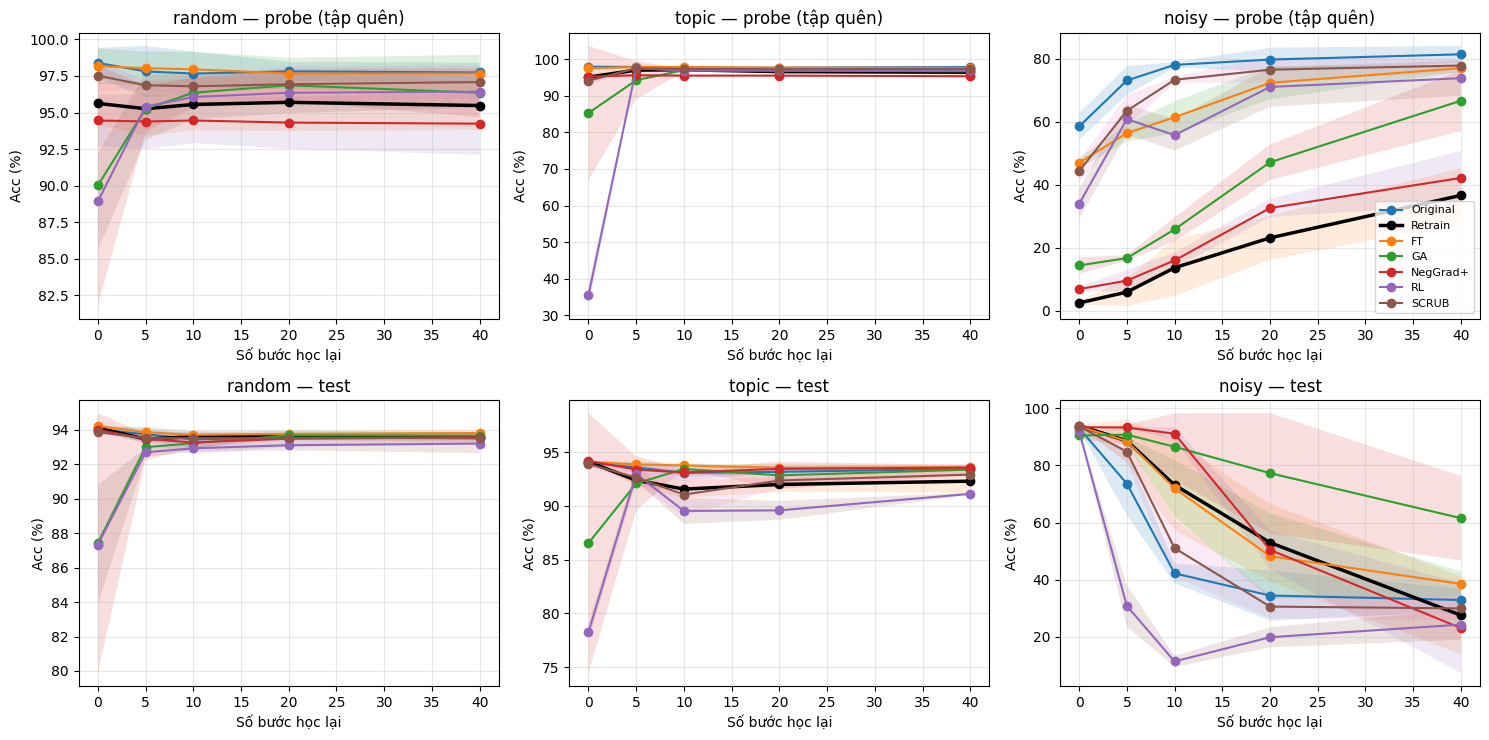

acc_probe                         acc_test              \
step                       0     5     10    20    40       0     5     10   
mode   method                                                                
noisy  FT                47.0  56.4  61.4  72.4  77.0     93.7  88.6  72.0   
       GA                14.4  16.7  25.8  47.1  66.7     90.5  90.8  86.5   
       GA (lr=5e-6)      28.1  47.4  59.1  73.0  79.6     93.0  93.7  89.1   
       NegGrad+           6.9   9.6  16.0  32.6  42.2     93.4  93.3  91.1   
       Original          58.5  73.1  78.0  79.7  81.4     93.1  73.6  42.2   
       RL                33.9  60.8  55.7  71.0  73.8     92.0  30.8  11.3   
       RL (lr=1e-5)      44.1  71.6  71.0  78.2  78.5     92.0  67.1  28.9   
       Retrain            2.5   5.9  13.6  23.1  36.6     94.0  88.6  73.1   
       SCRUB             44.3  63.5  73.3  76.5  77.8     93.7  84.8  51.0   
random FT                98.2  98.0  98.0  97.7  97.7     94.2  93.9  93.7   
       GA                90.0  95.3  96.4  96.9  96.4     87.4  93.0  93.2   
       GA (lr=5e-6)      96.6  96.4  97.0  97.4  96.9     93.5  93.3  93.5   
       NegGrad+          94.5  94.4  94.5  94.3  94.2     94.0  93.5  93.3   
       Original          98.4  97.8  97.7  97.8  97.7     94.0  93.8  93.5   
       RL                88.9  95.4  96.1  96.4  96.4     87.3  92.7  92.9   
       RL (lr=1e-5)      70.8  97.4  96.5  96.9  97.2     71.5  93.7  93.0   
       Retrain           95.6  95.3  95.6  95.7  95.5     94.1  93.5  93.6   
       SCRUB             97.5  96.9  96.8  96.9  97.1     93.9  93.5  93.5   
topic  FT                97.5  97.8  97.8  97.7  97.6     94.1  93.9  93.8   
       GA                85.3  94.2  97.0  96.8  96.6     86.5  92.1  93.4   
       GA (lr=5e-6)      96.4  97.5  97.3  97.1  97.1     93.7  93.4  93.3   
       NegGrad+          95.2  95.6  95.5  95.5  95.3     94.2  93.4  93.1   
       Original          97.9  97.8  97.7  97.7  97.8     94.0  93.6  93.1   
       RL                35.5  97.5  96.8  96.9  96.9     78.3  92.9  89.5   
       RL (lr=1e-5)      34.3  96.9  97.3  97.0  97.2     68.6  93.9  92.3   
       Retrain           95.1  97.0  97.1  96.6  96.4     94.1  92.4  91.6   
       SCRUB             94.1  97.5  97.3  97.2  97.3     93.9  92.6  91.1   

                                 
step                   20    40  
mode   method                    
noisy  FT            48.2  38.5  
       GA            77.3  61.5  
       GA (lr=5e-6)  63.2  46.7  
       NegGrad+      50.4  23.0  
       Original      34.4  32.9  
       RL            19.8  24.2  
       RL (lr=1e-5)  32.3  34.2  
       Retrain       53.0  27.5  
       SCRUB         30.5  29.9  
random FT            93.8  93.8  
       GA            93.7  93.7  
       GA (lr=5e-6)  93.7  93.7  
       NegGrad+      93.5  93.6  
       Original      93.6  93.5  
       RL            93.1  93.2  
       RL (lr=1e-5)  93.2  93.3  
       Retrain       93.6  93.6  
       SCRUB         93.5  93.5  
topic  FT            93.5  93.6  
       GA            92.8  93.4  
       GA (lr=5e-6)  93.4  93.5  
       NegGrad+      93.4  93.6  
       Original      93.2  93.5  
       RL            89.6  91.1  
       RL (lr=1e-5)  91.2  92.4  
       Retrain       92.0  92.3  
       SCRUB         92.4  92.9

In [11]:
import matplotlib.pyplot as plt
modes_present = [m for m in CFG["modes"] if m in set(rl["mode"])]
fig, axes = plt.subplots(2, len(modes_present), figsize=(5 * len(modes_present), 7.5), squeeze=False)
for j, mode in enumerate(modes_present):
    for i, col in enumerate(["acc_probe", "acc_test"]):
        ax = axes[i][j]
        d = rl[rl["mode"] == mode].groupby(["method", "step"])[col].agg(["mean", "std"]).reset_index()
        for m in MAIN:
            dm = d[d.method == m]
            if dm.empty: continue
            style = dict(lw=2.5, color="black") if m == "Retrain" else dict(lw=1.5)
            ax.plot(dm["step"], dm["mean"], marker="o", label=m, **style)
            ax.fill_between(dm["step"], dm["mean"] - dm["std"].fillna(0), dm["mean"] + dm["std"].fillna(0), alpha=0.15)
        ax.set_title(f"{mode} — {'probe (tập quên)' if col == 'acc_probe' else 'test'}")
        ax.set_xlabel("Số bước học lại"); ax.set_ylabel("Acc (%)"); ax.grid(alpha=0.3)
axes[0][-1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/relearn_attack.png", dpi=200); plt.show()

rl_table = rl.groupby(["mode", "method", "step"])[["acc_probe", "acc_test"]].mean().unstack("step").round(1)
display(rl_table)
rl_table.to_csv(f"{CFG['out_dir']}/summary_relearn.csv")

### Biểu đồ tổng quan

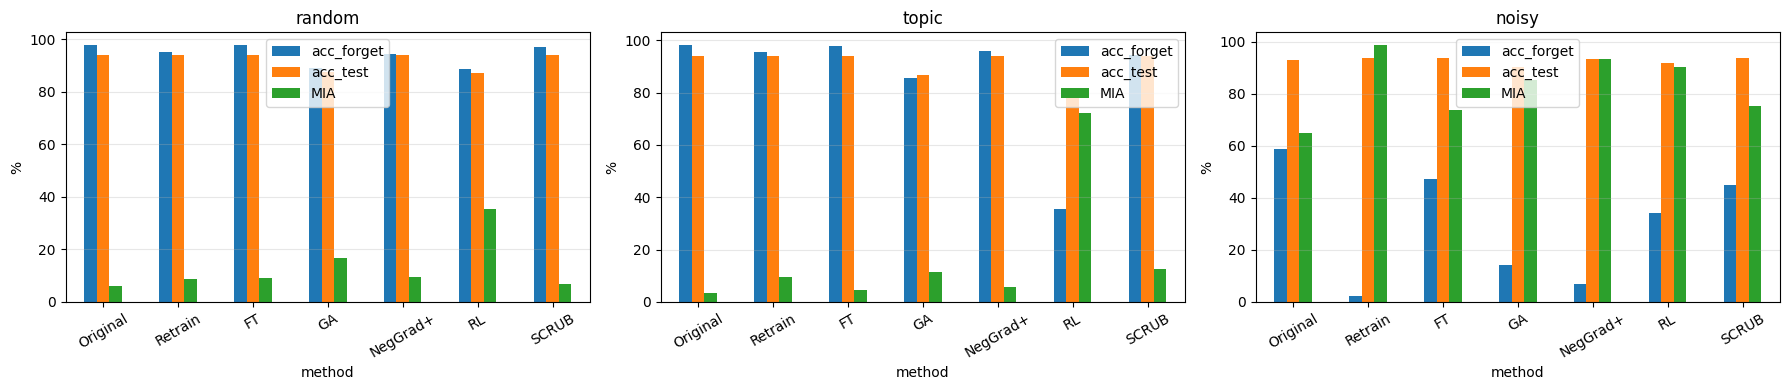

In [12]:
fig, axes = plt.subplots(1, len(modes_present), figsize=(6 * len(modes_present), 4), squeeze=False)
for ax, mode in zip(axes[0], modes_present):
    d = res[res["mode"] == mode].groupby("method")[["acc_forget", "acc_test", "MIA"]].mean()
    d.reindex([m for m in MAIN if m in d.index]).plot.bar(ax=ax, rot=30)
    ax.set_title(mode); ax.set_ylabel("%"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/overview.png", dpi=200); plt.show()

In [14]:
from huggingface_hub import login
login()

train.csv:   0%|          | 0.00/1.62M [00:00<?, ?B/s]

dev.csv:   0%|          | 0.00/177k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

... (212 outputs left out)


===== Gap so với Retrain trên hai bộ dữ liệu (càng nhỏ càng tốt) =====


UIT-VSFC                                 UIT-ViHSD  \
mode             noisy        random         topic         noisy   
method                                                             
Original   22.8 ± 1.06   1.34 ± 0.46   2.26 ± 0.15  19.75 ± 1.19   
Retrain      0.0 ± 0.0     0.0 ± 0.0     0.0 ± 0.0     0.0 ± 0.0   
FT         17.59 ± 0.4   1.01 ± 0.18   1.99 ± 0.31  16.59 ± 1.89   
GA         8.29 ± 1.81    7.36 ± 7.6   9.1 ± 12.34  27.64 ± 0.23   
NegGrad+     2.9 ± 0.3   0.68 ± 0.29    1.24 ± 0.2   5.07 ± 0.18   
RL        11.22 ± 0.66  11.98 ± 4.32  38.23 ± 3.77    7.5 ± 1.66   
SCRUB      16.62 ± 1.3   1.05 ± 0.42   1.05 ± 0.43  15.58 ± 0.92   

                         
mode             random  
method                   
Original    2.22 ± 1.25  
Retrain       0.0 ± 0.0  
FT          2.32 ± 1.41  
GA        30.79 ± 31.15  
NegGrad+    1.06 ± 0.38  
RL          7.64 ± 0.86  
SCRUB        1.71 ± 1.2


===== Xếp hạng theo Gap (1 = tốt nhất) =====


dataset  UIT-VSFC              UIT-ViHSD        Hạng TB
mode        noisy random topic     noisy random        
method                                                 
NegGrad+      1.0    1.0   2.0       1.0    1.0     1.2
SCRUB         4.0    3.0   1.0       3.0    2.0     2.6
FT            5.0    2.0   3.0       4.0    3.0     3.4
RL            3.0    5.0   5.0       2.0    4.0     3.8
GA            2.0    4.0   4.0       5.0    5.0     4.0

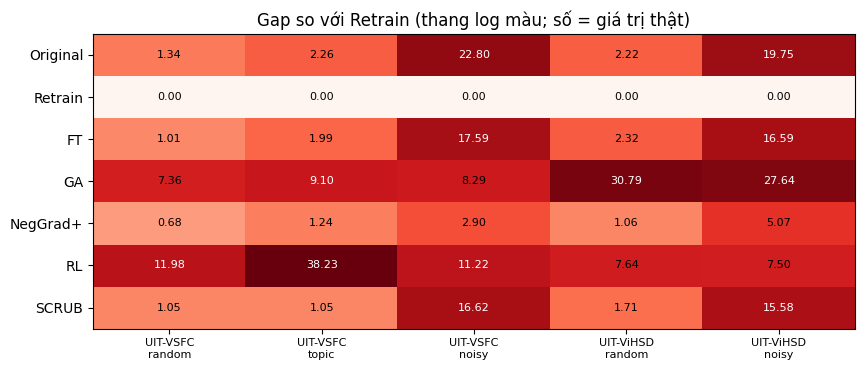

Đã lưu mọi file vào: /content/drive/MyDrive/unlearning_vsfc/results_v2_vihsd
Gợi ý: chạy lại các ô ở mục 6 (Tổng hợp kết quả) để có hình relearning cho ViHSD trong cùng thư mục.


In [15]:
# ===================== BỘ DỮ LIỆU THỨ HAI: UIT-ViHSD =====================
# Dán ô này vào CUỐI notebook PhoBERT, chạy SAU khi đã Run all (cần các hàm encode/setup/run/... có sẵn).
# Kết quả lưu vào thư mục riêng "<out_dir>_vihsd", không lẫn với UIT-VSFC. Nếu Colab ngắt: Run all lại
# (phần UIT-VSFC sẽ tự bỏ qua vì đã có kết quả), rồi chạy lại ô này — phần ViHSD đã xong cũng được bỏ qua.
DS2 = dict(
    hf_name="sonlam1102/vihsd",
    modes=["random", "noisy"],   # ViHSD không có nhãn chủ đề nên bỏ kịch bản topic
    seeds=CFG["seeds"],
    max_train=12000,             # lấy mẫu con cho cỡ tương đương UIT-VSFC (~11k) để tiết kiệm GPU; None = dùng toàn bộ
)
OUT1 = CFG["out_dir"]
OUT2 = OUT1.rstrip("/") + "_vihsd"
os.makedirs(OUT2, exist_ok=True)

# ---------- 1) Tải dữ liệu, tự nhận diện cột văn bản và cột nhãn ----------
raw = load_dataset(DS2["hf_name"])
print(raw)
_df0 = raw["train"].to_pandas()
TEXT_COL = max([c for c in _df0.columns
                 if _df0[c].dtype == object or pd.api.types.is_string_dtype(_df0[c])],
               key=lambda c: _df0[c].astype(str).str.len().mean())
LABEL_COL = [c for c in _df0.columns if c != TEXT_COL and _df0[c].nunique() <= 10][0]
CLASSES = sorted(_df0[LABEL_COL].dropna().unique().tolist())
LAB2ID = {c: i for i, c in enumerate(CLASSES)}
print(f"Cột văn bản: {TEXT_COL} | cột nhãn: {LABEL_COL} | các nhãn: {CLASSES}")

def prep_vihsd(split):
    df = raw[split].to_pandas()
    df = df[df[TEXT_COL].notna() & df[LABEL_COL].notna()].reset_index(drop=True)
    df["text"] = df[TEXT_COL].astype(str).map(ViTokenizer.tokenize)
    df["sentiment"] = df[LABEL_COL].map(LAB2ID).astype(int)   # đặt tên 'sentiment' để dùng lại hàm encode
    df["topic"] = 0
    return df

train_df, test_df = prep_vihsd("train"), prep_vihsd("test")
if DS2["max_train"] and len(train_df) > DS2["max_train"]:
    train_df = train_df.sample(DS2["max_train"], random_state=0).reset_index(drop=True)
print({"train": len(train_df), "test": len(test_df)})
print("Phân bố nhãn train:", train_df["sentiment"].value_counts().sort_index().to_dict())

# ---------- 2) Thay dữ liệu toàn cục để các hàm có sẵn chạy trên ViHSD ----------
NUM_LABELS = len(CLASSES)
train_ids, train_mask, train_y_clean = encode(train_df)
test_ds = TensorDataset(*encode(test_df))
train_topics, test_topics = train_df["topic"].values, test_df["topic"].values
TOPICS = ["all"]

# ---------- 3) Chạy thí nghiệm ----------
orig_cache2 = {}
for mode in DS2["modes"]:
    for seed in DS2["seeds"]:
        f_res, f_rl = f"{OUT2}/results_{mode}_seed{seed}.csv", f"{OUT2}/relearn_{mode}_seed{seed}.csv"
        if os.path.exists(f_res) and os.path.exists(f_rl):
            print(f"[ViHSD] Đã có kết quả {mode}/seed{seed}, bỏ qua."); continue
        df_, cv_ = run(mode, seed, orig_cache2)
        df_.to_csv(f_res, index=False); cv_.to_csv(f_rl, index=False)
        print("[ViHSD] Đã lưu", f_res)

# ---------- 4) Tổng hợp ----------
ORDER2 = ["Original", "Retrain", "FT", "GA", "NegGrad+", "RL", "SCRUB", "GA (lr=5e-6)", "RL (lr=1e-5)"]
MAIN2 = ORDER2[:7]

def load_results(folder):
    r = pd.concat([pd.read_csv(f) for f in glob.glob(f"{folder}/results_*.csv")], ignore_index=True)
    cols = ["acc_retain", "acc_forget", "acc_test", "MIA"]
    ref_ = r[r.method == "Retrain"].set_index(["mode", "seed"])
    r["Gap"] = [(x[cols] - ref_.loc[(x["mode"], x["seed"]), cols]).abs().mean() for _, x in r.iterrows()]
    r["dForget"] = [abs(x["acc_forget"] - ref_.loc[(x["mode"], x["seed"]), "acc_forget"]) for _, x in r.iterrows()]
    r["dMIA"] = [abs(x["MIA"] - ref_.loc[(x["mode"], x["seed"]), "MIA"]) for _, x in r.iterrows()]
    return r

def ms(d, cols, order):
    g = d.groupby("method")[cols]
    out = g.mean().round(2).astype(str) + " ± " + g.std().fillna(0).round(2).astype(str)
    return out.reindex([m for m in order if m in out.index])

res2 = load_results(OUT2)
rl2 = pd.concat([pd.read_csv(f) for f in glob.glob(f"{OUT2}/relearn_*.csv")], ignore_index=True)

main_cols = ["acc_retain", "acc_forget", "acc_test", "f1_test", "MIA", "Gap", "dForget", "dMIA", "time_s"]
for mode in DS2["modes"]:
    d = res2[res2["mode"] == mode]
    if d.empty: continue
    print(f"\n===== [ViHSD] Bảng chính: {mode} (n seed = {d.seed.nunique()}) =====")
    t = ms(d, main_cols, ORDER2); display(t); t.to_csv(f"{OUT2}/summary_{mode}.csv")
if "noisy" in set(res2["mode"]):
    mem = res2[(res2["mode"] == "noisy") & (res2.method == "Original")].set_index("seed")["acc_forget"]
    print("\n[ViHSD] Mức ghi nhớ nhãn nhiễu của Original theo seed:", mem.round(1).to_dict())

rl_t = rl2.groupby(["mode", "method", "step"])[["acc_probe", "acc_test"]].mean().unstack("step").round(1)
print("\n===== [ViHSD] Relearning attack (trung bình qua seed) =====")
display(rl_t); rl_t.to_csv(f"{OUT2}/summary_relearn.csv")

# ---------- 5) So sánh hai bộ dữ liệu: Gap so với Retrain ----------
res1 = load_results(OUT1)
def gap_table(r, name):
    g = r.groupby(["method", "mode"])["Gap"]
    t = g.mean().round(2).astype(str) + " ± " + g.std().fillna(0).round(2).astype(str)
    t = t.unstack("mode")
    t.columns = pd.MultiIndex.from_product([[name], t.columns])
    return t
cross = pd.concat([gap_table(res1, "UIT-VSFC"), gap_table(res2, "UIT-ViHSD")], axis=1).reindex(MAIN2)
print("\n===== Gap so với Retrain trên hai bộ dữ liệu (càng nhỏ càng tốt) =====")
display(cross)
cross.to_csv(f"{OUT2}/cross_dataset_gap.csv"); cross.to_latex(f"{OUT2}/cross_dataset_gap.tex", escape=True)

# Xếp hạng trung bình của các phương pháp unlearning (không tính Original/Retrain) qua mọi (bộ dữ liệu, kịch bản)
allr = pd.concat([res1.assign(dataset="UIT-VSFC"), res2.assign(dataset="UIT-ViHSD")])
um = allr[allr.method.isin(MAIN2[2:])].groupby(["dataset", "mode", "method"])["Gap"].mean().reset_index()
um["rank"] = um.groupby(["dataset", "mode"])["Gap"].rank()
rank = um.pivot_table(index="method", columns=["dataset", "mode"], values="rank")
rank["Hạng TB"] = rank.mean(1)
rank = rank.sort_values("Hạng TB").round(2)
print("\n===== Xếp hạng theo Gap (1 = tốt nhất) =====")
display(rank); rank.to_csv(f"{OUT2}/cross_dataset_rank.csv")

# Hình: bản đồ nhiệt Gap (phương pháp × bộ dữ liệu/kịch bản), lưu PNG + PDF
import matplotlib.pyplot as plt
h = allr.groupby(["method", "dataset", "mode"])["Gap"].mean().unstack(["dataset", "mode"]).reindex(MAIN2)
h = h[[c for c in [("UIT-VSFC", m) for m in ["random", "topic", "noisy"]] + [("UIT-ViHSD", m) for m in DS2["modes"]] if c in h.columns]]
fig, ax = plt.subplots(figsize=(1.25 * h.shape[1] + 2.5, 3.8))
im = ax.imshow(np.log10(h.values + 0.1), cmap="Reds", aspect="auto")
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        v = h.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if np.log10(v + 0.1) > np.log10(np.nanmax(h.values) + 0.1) * 0.6 else "black")
ax.set_xticks(range(h.shape[1])); ax.set_xticklabels([f"{d}\n{m}" for d, m in h.columns], fontsize=8)
ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
ax.set_title("Gap so với Retrain (thang log màu; số = giá trị thật)")
plt.tight_layout()
plt.savefig(f"{OUT2}/fig_cross_dataset_gap.png", dpi=300); plt.savefig(f"{OUT2}/fig_cross_dataset_gap.pdf"); plt.show()

# Để vẽ lại các hình relearning/tổng quan cho ViHSD: chạy lại các ô ở mục 6 của notebook (sau ô này).
CFG["out_dir"], CFG["modes"] = OUT2, DS2["modes"]
print("Đã lưu mọi file vào:", OUT2)
print("Gợi ý: chạy lại các ô ở mục 6 (Tổng hợp kết quả) để có hình relearning cho ViHSD trong cùng thư mục.")
